# NLP Project 2 — 01. ART data and Transformer tokenization

**Status:** DataLoader smoke test completed in terminal; this notebook is for reproducible exploration and documentation.  
**Model family:** BERT-Base (`google-bert/bert-base-uncased`)  
**Dataset:** [`amarfurt/art-nlp-hs26`](https://huggingface.co/datasets/amarfurt/art-nlp-hs26)

## Purpose

Verify the training-data schema and labels, inspect candidate-wise BERT tokenization, document the maximum sequence length, and test dynamic batching. **No model fitting, checkpoint selection or official test-set evaluation is performed here.**

**Design rule:** reusable code lives in `project2/src/`; this notebook imports and checks it rather than maintaining a second implementation.

## 1. Environment and imports

Select your existing **`nlp-art-hs26`** Conda interpreter/kernel in PyCharm or Jupyter. The code below works when launched either from the repository root or from `project2/notebooks/`.

In [1]:
import sys
from pathlib import Path
from collections import Counter

import numpy as np
import torch
from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import AutoTokenizer

repo_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "project2" / "src" / "data_loader.py").is_file()),
    None,
)
assert repo_root is not None, "Open the notebook inside the nlp-art-hs26-kim repository."
sys.path.insert(0, str(repo_root / "project2" / "src"))

from data_loader import ARTDataset, ARTCollator, MAX_LENGTH, MODEL_NAME

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Repository:", repo_root)
print("Tokenizer:", MODEL_NAME, "| configured limit:", MAX_LENGTH)

C:\Users\kimbo\anaconda3\envs\nlp-art-hs26\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.17
PyTorch: 2.14.1+cu130
CUDA available: True
Repository: C:\Users\kimbo\Documents\HSLU\Sem 5\NLP\nlp-art-hs26-kim
Tokenizer: google-bert/bert-base-uncased | configured limit: 128


## 2. Official training split and label semantics

The course specifies **16,801 training**, **1,000 validation**, and **1,532 test** examples. Here we **load only training**. The ART labels refer to the correct hypothesis number (1 or 2), while PyTorch cross-entropy expects class indices 0 and 1.  

Note: the dataset's `ClassLabel` metadata lists `0`, `1`, and `2`, but this alone does not imply that all three labels occur. Check the actual distribution.

In [2]:
raw_train = load_dataset("amarfurt/art-nlp-hs26", split="train")
required = {"observation_1", "observation_2", "hypothesis_1", "hypothesis_2", "label"}
assert required.issubset(raw_train.column_names)
assert len(raw_train) == 16801

label_counts = dict(sorted(Counter(raw_train["label"]).items()))
assert set(label_counts) == {1, 2}, f"Unexpected labels: {label_counts}"

print("Columns:", raw_train.column_names)
print("Label feature:", raw_train.features["label"])
print("Counts:", label_counts)
print("Proportions:", {k: round(v / len(raw_train), 4) for k, v in label_counts.items()})
print("Target mapping: original 1 -> class 0; original 2 -> class 1")

Columns: ['observation_1', 'observation_2', 'hypothesis_1', 'hypothesis_2', 'label']
Label feature: ClassLabel(names=['0', '1', '2'])
Counts: {1: 8461, 2: 8340}
Proportions: {1: 0.5036, 2: 0.4964}
Target mapping: original 1 -> class 0; original 2 -> class 1


## 3. Candidate-wise encoding

Proposed encoding of **each** hypothesis:

`[CLS] Observation 1 [SEP] Hypothesis [SEP] Observation 2 [SEP]`

Two candidate strings are encoded independently and then scored by **one shared encoder and classifier**, giving two logits per example.

**Preprocessing decisions:** use the pretrained uncased BERT WordPiece tokenizer; retain punctuation, negation and word order; no stemming, lemmatization or stopword removal. The present implementation does not explicitly supply token-type IDs, so the encoder uses its default single segment type. We use four special tokens per candidate. This is a design choice to justify, not an assignment requirement.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
train_dataset = ARTDataset("train", tokenizer, max_length=MAX_LENGTH)

for i in range(2):
    row = train_dataset[i]
    print(f"\nExample {i} | original label={raw_train[i]['label']} | target={row['label']}")
    for j, ids in enumerate(row["input_ids"], start=1):
        print(f"Candidate {j} ({len(ids)} tokens):", tokenizer.decode(ids))

assert [train_dataset[i]["label"] for i in range(3)] == [1, 1, 0]
assert [len(x) for x in train_dataset[0]["input_ids"]] == [32, 37]
print("\nCandidate encoding sanity checks: OK")


Example 0 | original label=2 | target=1
Candidate 1 (32 tokens): [CLS] a baby panda was lost in the woods. [SEP] he was never lost. [SEP] he was reunited with his parents, who also lived at the zoo. [SEP]
Candidate 2 (37 tokens): [CLS] a baby panda was lost in the woods. [SEP] all the people from the zoo looked for him. [SEP] he was reunited with his parents, who also lived at the zoo. [SEP]

Example 1 | original label=2 | target=1
Candidate 1 (34 tokens): [CLS] a bank teller told me to rob the bank where she worked. [SEP] the mountain told me when no one would be there. [SEP] we split the money equally. [SEP]
Candidate 2 (34 tokens): [CLS] a bank teller told me to rob the bank where she worked. [SEP] the teller told me when no one would be there. [SEP] we split the money equally. [SEP]

Candidate encoding sanity checks: OK


## 4. Length statistics and truncation policy

Lengths are measured **after BERT tokenization**, including `[CLS]` and `[SEP]` tokens. The proposed `max_length=128` should cause no truncation in the official training split; the Dataset currently **raises an exception** instead of silently truncating if this assumption fails. This is useful during debugging. We will check evaluation splits without using their labels/results for tuning.

In [4]:
lengths = np.array(
    [len(ids) for sample in train_dataset.samples for ids in sample["input_ids"]],
    dtype=np.int32,
)
print("Training examples:", len(train_dataset))
print("Candidate sequences:", len(lengths))
print(f"Mean: {lengths.mean():.1f} | Median: {np.median(lengths):.0f}")
print(f"P95: {np.percentile(lengths, 95):.0f} | P99: {np.percentile(lengths, 99):.0f}")
print("Maximum:", lengths.max())
for limit in [64, 96, 128, 256, 512]:
    truncated = int(np.sum(lengths > limit))
    print(f"Longer than {limit}: {truncated} / {len(lengths)} ({truncated / len(lengths):.2%})")
assert int(lengths.max()) <= MAX_LENGTH
print("Training-set truncation check: OK")

Training examples: 16801
Candidate sequences: 33602
Mean: 34.6 | Median: 34
P95: 44 | P99: 50
Maximum: 66
Longer than 64: 1 / 33602 (0.00%)
Longer than 96: 0 / 33602 (0.00%)
Longer than 128: 0 / 33602 (0.00%)
Longer than 256: 0 / 33602 (0.00%)
Longer than 512: 0 / 33602 (0.00%)
Training-set truncation check: OK


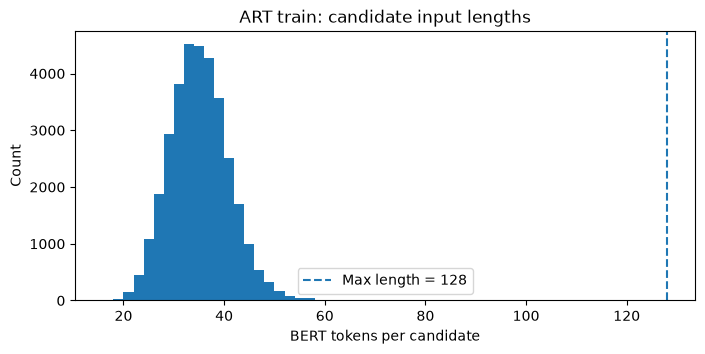

In [5]:
# Optional visualization (matplotlib is typically present in NLP/ML environments).
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib not installed; numeric length statistics above are sufficient.")
else:
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.hist(lengths, bins=25)
    ax.axvline(MAX_LENGTH, linestyle="--", label=f"Max length = {MAX_LENGTH}")
    ax.set(xlabel="BERT tokens per candidate", ylabel="Count", title="ART train: candidate input lengths")
    ax.legend()
    plt.show()

## 5. Dynamic padding and tensor shapes

The collator pads the two candidates of every example to the **longest candidate in the current batch**. In training, the same BERT weights score each candidate:

- `input_ids`: `[B, 2, L_batch]`
- `attention_mask`: `[B, 2, L_batch]` (1 = content, 0 = padding)
- `labels`: `[B]` with values 0 or 1

This improves efficiency compared with padding every batch to a fixed 128 tokens.

In [6]:
loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=False,  # deterministic for this inspection; training will shuffle
    collate_fn=ARTCollator(tokenizer.pad_token_id),
)
batch = next(iter(loader))
print("input_ids:", tuple(batch["input_ids"].shape))
print("attention_mask:", tuple(batch["attention_mask"].shape))
print("labels:", tuple(batch["labels"].shape), batch["labels"].tolist())
print("First candidate lengths:", batch["attention_mask"][0].sum(dim=1).tolist())

assert batch["input_ids"].shape == (4, 2, 37)
assert batch["attention_mask"].shape == batch["input_ids"].shape
assert batch["labels"].shape == (4,)
assert batch["labels"].tolist() == [1, 1, 0, 0]
assert batch["attention_mask"][0].sum(dim=1).tolist() == [32, 37]
assert torch.all(batch["input_ids"][batch["attention_mask"] == 0] == tokenizer.pad_token_id)
assert torch.all(batch["attention_mask"][batch["input_ids"] != tokenizer.pad_token_id] == 1)
print("Dynamic padding and label checks: OK")

input_ids: (4, 2, 37)
attention_mask: (4, 2, 37)
labels: (4,) [1, 1, 0, 0]
First candidate lengths: [32, 37]
Dynamic padding and label checks: OK
